# Load the simulation

In [3]:
import yt
import helper_functions as hf
import matplotlib.pyplot as plt
from astropy.table import Table
import numpy as np

In [4]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

In [12]:
target_sink = 36
output = 59

In [13]:
ds=yt.load(hf.info_file(output, df))

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00059/info_00059.txt


yt : [INFO     ] 2026-11-06 13:31:45,440 Parameters: current_time              = 0.5481856319558245 Gyr
yt : [INFO     ] 2026-11-06 13:31:45,441 Parameters: domain_dimensions         = [128 128 128]
yt : [INFO     ] 2026-11-06 13:31:45,441 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-11-06 13:31:45,442 Parameters: domain_right_edge         = [1. 1. 1.]
yt : [INFO     ] 2026-11-06 13:31:45,443 Parameters: cosmological_simulation   = True
yt : [INFO     ] 2026-11-06 13:31:45,444 Parameters: current_redshift          = 8.999677625143491
yt : [INFO     ] 2026-11-06 13:31:45,444 Parameters: omega_lambda              = 0.693499982357025
yt : [INFO     ] 2026-11-06 13:31:45,445 Parameters: omega_matter              = 0.306499987840652
yt : [INFO     ] 2026-11-06 13:31:45,445 Parameters: omega_radiation           = 0.0
yt : [INFO     ] 2026-11-06 13:31:45,446 Parameters: hubble_constant           = 0.6790000152587891


In [14]:
ts=hf.SinkDataLoader(df, sinkid=target_sink)
index = np.argmin(np.abs(ts.data["z"] - ds.current_redshift))

bondi = ts.data["Rb"][index]
bhl = ts.data["Rbhl"][index]

print(bondi, ts.data["Rb"].unit)
print(bhl, ts.data["Rbhl"].unit)

3.38960114584646 pc
0.069377534169613 pc


# Centre plot on the target black hole

In [15]:
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

This output contains 217 black holes


In [16]:
sink_pos=t[t['sink_id']==target_sink]['x', 'y', 'z']
sink_vel=t[t['sink_id']==target_sink]['vx', 'vy', 'vz']
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(), 'code_length')
sink_vel_ds=ds.arr(sink_vel[0].as_void().tolist(), 'code_velocity')

print(sink_pos_ds)
print(sink_vel_ds)
print(ds.index.get_smallest_dx().to('kpc'))

[0.5041305  0.49993548 0.50387598] code_length
[-4.72055320e-05  5.34193555e-04  7.47836797e-05] code_velocity


yt : [WARNING  ] 2026-11-06 13:31:50,944 The DM particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,945 The star particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,945 The cloud particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,946 The dust particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,947 The star_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,947 The cloud_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,948 The dust_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-06 13:31:50,949 The gas_tracer particle filter already exists. Overriding.
yt : [INFO     ] 2026-11-06 13:31:50,950 Adding particle_type: DM
yt : [INFO     ] 2026-11-06 13:31:50,970 Adding particle_type: star
yt : [INFO     ] 2026-11-06 13:31:50,991 Adding particle_type: cloud
yt : [INFO     ] 2

0.14019885867726098 kpc


yt : [INFO     ] 2026-11-06 13:32:15,390 Identified 90 intersecting domains
yt : [INFO     ] 2026-11-06 13:32:25,433 xlim = 0.504096 0.504165
yt : [INFO     ] 2026-11-06 13:32:25,436 ylim = 0.499901 0.499969
yt : [INFO     ] 2026-11-06 13:32:25,441 xlim = 0.504096 0.504165
yt : [INFO     ] 2026-11-06 13:32:25,442 ylim = 0.499901 0.499969
yt : [INFO     ] 2026-11-06 13:32:25,445 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



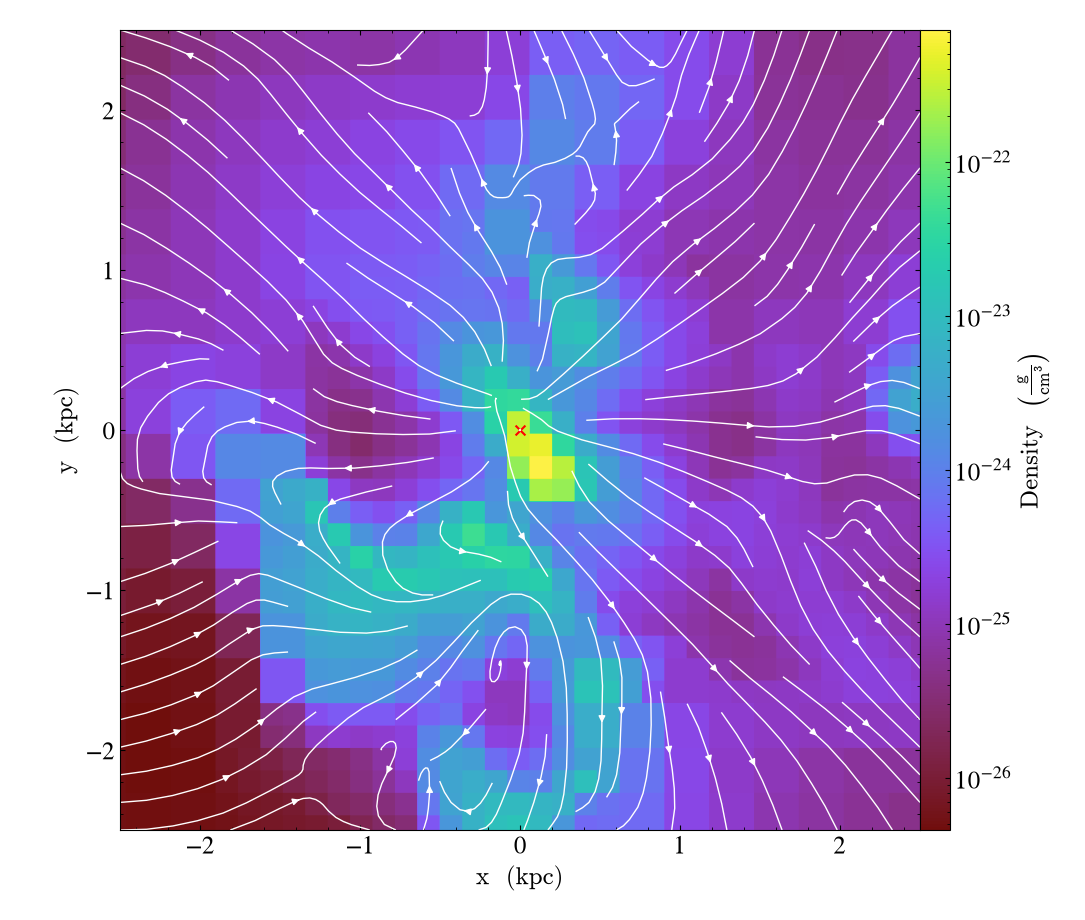

yt : [INFO     ] 2026-11-06 13:32:26,931 Saving plot fig/snapshots/stream_line_36_59_Slice_z_density.png


['fig/snapshots/stream_line_36_59_Slice_z_density.png']

In [ ]:
fp = {"center": sink_pos_ds, "bulk_velocity": sink_vel_ds} 

s = yt.SlicePlot(ds, "z", ("gas", "density"), center=sink_pos_ds, width=(5, "kpc"), field_parameters=fp)
s.annotate_streamlines(("gas", "relative_velocity_x"), ("gas", "relative_velocity_y"), color='white')
s.annotate_marker(sink_pos_ds, coord_system='data', color='red')
s.annotate_sphere(sink_pos_ds, radius=(bondi, 'pc'), circle_args={"color": "white"})
s.annotate_sphere(sink_pos_ds, radius=(bhl, 'pc'), circle_args={"color": "black"})
s.show()
# s.save(f'fig/snapshots/stream_line_{target_sink}_{output}')

yt : [INFO     ] 2026-11-06 13:32:47,769 Identified     4/  512 intersecting domains (    4 through hilbert key indexing)
yt : [INFO     ] 2026-11-06 13:32:47,822 Projection completed
yt : [INFO     ] 2026-11-06 13:32:47,823 xlim = 0.504096 0.504165
yt : [INFO     ] 2026-11-06 13:32:47,823 ylim = 0.499901 0.499969
yt : [INFO     ] 2026-11-06 13:32:47,826 xlim = 0.504096 0.504165
yt : [INFO     ] 2026-11-06 13:32:47,827 ylim = 0.499901 0.499969
yt : [INFO     ] 2026-11-06 13:32:47,828 Making a fixed resolution buffer of (('gas', 'radial_velocity')) 800 by 800
yt : [INFO     ] 2026-11-06 13:32:48,091 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-11-06 13:32:49,643 Projection completed



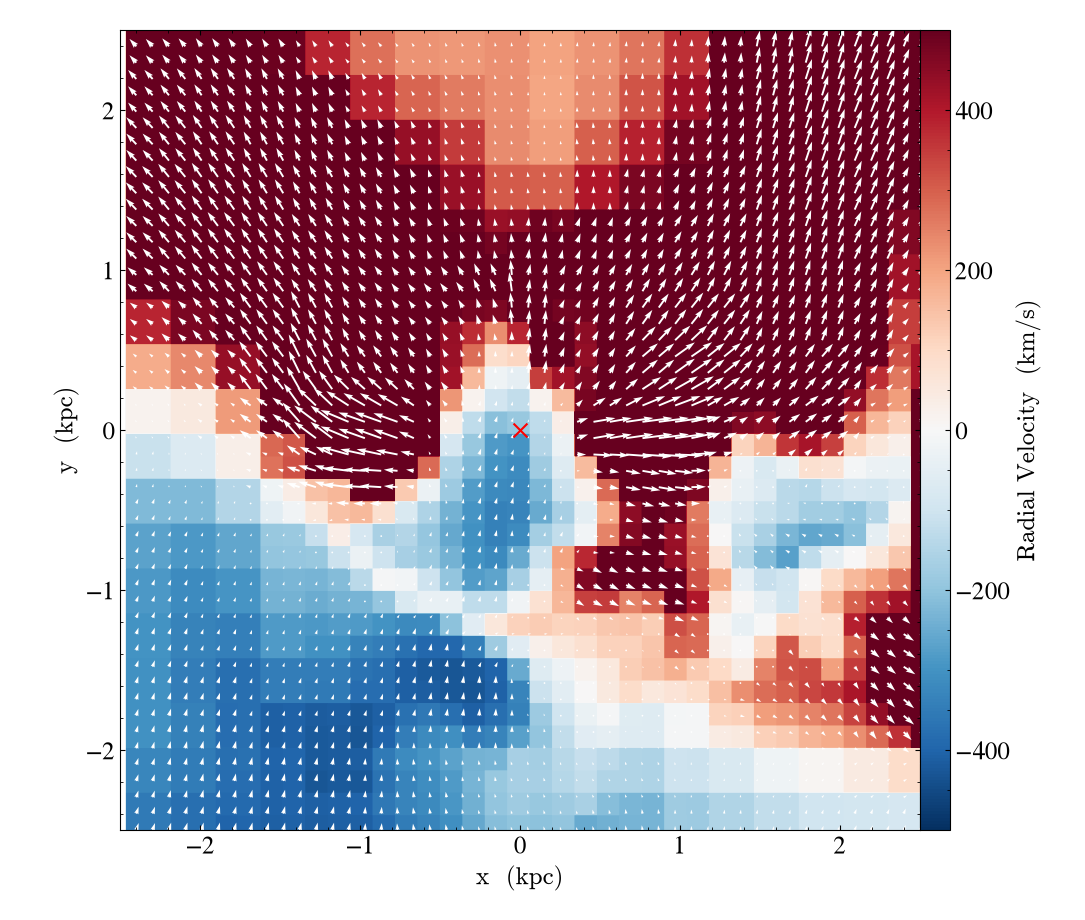
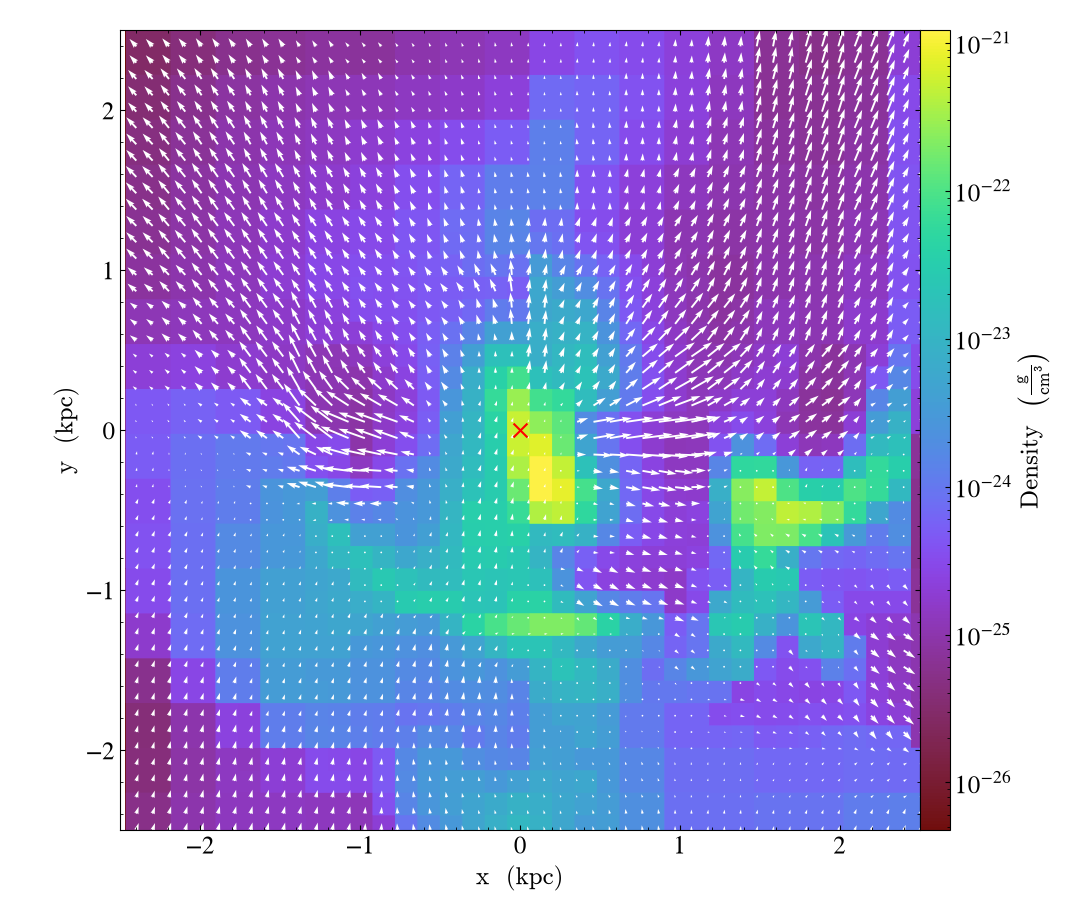

yt : [INFO     ] 2026-11-06 13:32:50,112 Saving plot fig/snapshots/quiver_36_59_Projection_z_radial_velocity_density.png
yt : [INFO     ] 2026-11-06 13:32:50,382 Saving plot fig/snapshots/quiver_36_59_Projection_z_density_density.png


['fig/snapshots/quiver_36_59_Projection_z_radial_velocity_density.png',
 'fig/snapshots/quiver_36_59_Projection_z_density_density.png']

In [ ]:
width = ds.quan(2.5, 'kpc')
height = ds.quan(1.0, 'kpc')
disk = ds.disk(sink_pos_ds, [0, 0, 1], width, height)

c = sink_pos_ds
half = ds.arr([2.5, 2.5, 1.0], "kpc")
box  = ds.box(c - half, c + half)

p = yt.ProjectionPlot(ds, "z", [("gas", "density"), ("gas", "radial_velocity")], center=sink_pos_ds, 
                      width=2 * width, data_source=box, field_parameters=fp, weight_field=('gas', 'density'))
p.set_unit(("gas", "radial_velocity"), "km/s")
p.set_log(("gas", "radial_velocity"), False)
p.set_cmap(("gas", "radial_velocity"), "RdBu_r")
p.set_zlim(("gas", "radial_velocity"), -500, 500)

p.annotate_quiver(("gas", "relative_velocity_x"),
                  ("gas", "relative_velocity_y"), factor=16, color="white")
p.annotate_marker(sink_pos_ds, coord_system="data", color="red", s=100)
p.show()
# p.save(f'fig/snapshots/quiver_{target_sink}_{output}')